# Forelesning 4: Kalibrering og sammenlikning av resultater

<div class="bilde-midt" style="width:32%">

![Panda](bilder/kalibrering.jpeg)
<p class="kreditering">Foto: Alina.Popova.26</a>, <a href="https://creativecommons.org/licenses/by/2.0/">CC BY 2.0</a>, via Wikimedia Commons</p>

</div>

I dag bruker vi statistikken fra forrige forelesning til to vanlige oppgaver i kjemi:

1. **Kalibrering:** Vi lager en kalibreringslinje og bestemmer konsentrasjonen i en ukjent prøve.
2. **Sammenlikning:** Avviker resultatet vårt fra en referanseverdi? Er to grupper eller to analysemetoder forskjellige?

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Repetisjon
### Gruppering med `groupby`

Ofte vil vi beregne den samme størrelsen for hver gruppe i et datasett, for eksempel for hver art, hvert ion eller hver konsentrasjon.

<div class="viktig">

`groupby` deler datarammen i grupper etter verdiene i en kolonne, gjør den samme beregningen på hver gruppe og samler resultatene i en tabell.

```python
data.groupby("gruppekolonne")["målekolonne"].mean()
```

Med `agg` kan vi beregne flere størrelser på én gang: `.agg(["count", "mean", "std"])`.

</div>

<div class="oppgave">

**Prøv selv:** Fila `flame_emission.csv` inneholder emisjonsintensitet ved 589, 671 og 766 nm for prøver med Na⁺, Li⁺ og K⁺.

1. Bruk `groupby` til å beregne antall målinger, gjennomsnitt og standardavvik for emisjonen ved **589 nm** for hvert ion.
2. Legg til en kolonne med RSD i prosent.
3. Hvilket ion gir sterkest signal ved 589 nm? Hvilket har best relativ presisjon?

</div>

In [5]:
flame = pd.read_csv("../datahandtering_visualisering/data/flame_emission.csv")
flame["emission_589_nm"]

0     91.37
1     89.16
2     85.72
3     85.25
4     88.06
5     90.56
6     89.87
7     87.10
8     85.61
9     86.96
10    89.34
11    90.02
12    88.43
13    86.50
14    86.32
15    87.95
16    89.58
17    89.49
18    87.76
19    86.24
20    17.37
21    15.16
22    11.72
23    11.25
24    14.06
25    16.56
26    15.87
27    13.10
28    11.61
29    12.96
30    15.34
31    16.02
32    14.43
33    12.50
34    12.32
35    13.95
36    15.58
37    15.49
38    13.76
39    12.24
40    15.37
41    13.16
42     9.72
43     9.25
44    12.06
45    14.56
46    13.87
47    11.10
48     9.61
49    10.96
50    13.34
51    14.02
52    12.43
53    10.50
54    10.32
55    11.95
56    13.58
57    13.49
58    11.76
59    10.24
Name: emission_589_nm, dtype: float64

In [6]:
summary = flame.groupby("ion")["emission_589_nm"].agg(["count", "mean", "std"])
summary["rsd_percent"] = summary["std"]/summary["mean"] * 100
summary

,count,mean,std,rsd_percent
ion,,,,
K,20,12.0645,1.807084,14.978523
Li,20,14.0645,1.807084,12.848547
Na,20,88.0645,1.807084,2.052000


<div class="diskuter">

**Diskuter:** Natriumflammen er gul, og den gule natrium-D-linja ligger ved 589 nm. Stemmer det med resultatet? Hvorfor er RSD høyest for ionene som gir svakt signal ved 589 nm?

</div>

## Del 1: Kalibrering

<div class="viktig">

I UV-Vis-spektroskopi sier **Beer-Lamberts lov** at absorbansen er proporsjonal med konsentrasjonen:

$$A = \varepsilon l c$$

Virkelige målinger ligger ikke perfekt på en linje, så vi tilpasser en rett linje til kalibreringsstandardene:

$$A = a c + b$$

En kalibreringsmodell gjelder bare i konsentrasjonsområdet vi har undersøkt.

</div>

### Se på dataene først

In [8]:
data = pd.read_csv("../datahandtering_visualisering/data/uvvis_calibration.csv")
data.head()

,sample_id,sample_type,concentration_uM,replicate,absorbance
0,blank_1,blank,0.0,1,0.010
1,blank_2,blank,0.0,2,0.011
2,std_2_1,standard,2.0,1,0.171
3,std_2_2,standard,2.0,2,0.169
4,std_2_3,standard,2.0,3,0.172


In [9]:
A_unknown = 0.42

### Lineær regresjon
`linregress` finner linja som ligger nærmest punktene samlet sett.

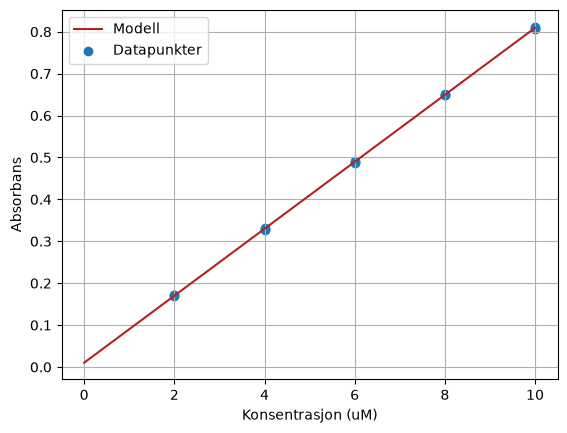

In [10]:
from scipy import stats

standards = data[data["sample_type"] == "standard"] 
kons = standards["concentration_uM"]
absorbans = standards["absorbance"]

reg = stats.linregress(kons, absorbans)
a = reg.slope
b = reg.intercept

x = np.linspace(0, max(kons), 100)
y = a*x + b

plt.plot(x, y, label = "Modell", color = "firebrick")
plt.scatter(kons, absorbans, label = "Datapunkter")
plt.xlabel("Konsentrasjon (uM)")
plt.ylabel("Absorbans")
plt.legend()
plt.grid()
plt.show()

<div class="diskuter">

**Diskuter:** Hva betyr stigningstallet og konstantleddet kjemisk? Hvilken enhet har de? Hvorfor bør vi ikke automatisk tvinge linja gjennom origo?

</div>

<div class="viktig">

- **Stigningstallet** er metodens **følsomhet**: hvor mye absorbansen øker per µmol/L. Følsomhet er ikke det samme som presisjon.
- **Konstantleddet** er signalet modellen forventer ved null konsentrasjon, for eksempel fra blankbidrag.
</div>

### Bestem den ukjente konsentrasjonen
Vi løser modellen med hensyn på konsentrasjonen:

$$c = \frac{A - b}{a}$$

<div class="oppgave">

**Finn feilen:** Programmet nedenfor gir 0,47 µmol/L. Se på kalibreringsfiguren. Er det rimelig? Finn og rett feilen.

</div>

In [17]:
ukjent = data[data["sample_type"] == "unknown"]
snitt_ukjent = ukjent["absorbance"].mean()
print(snitt_ukjent)

c_ukjent = (snitt_ukjent - b)/a
print(c_ukjent)

0.6043333333333334
7.435127242386316


<div class="viktig">

Dette er et **punktestimat**: vårt beste anslag, ikke et eksakt svar. Både replikatene til den ukjente prøven og selve kalibreringslinja har usikkerhet. Kontroller alltid at signalet ligger **innenfor** kalibreringsområdet.

</div>

<div class="oppgave">

**Prøv selv:** Tipp først: Hva skjer med stigningstallet og konstantleddet hvis vi legger til 0,01 i *alle* absorbansene, for eksempel fordi kyvetten er skitten? Kjør koden og sjekk.

</div>

In [ ]:
shifted = stats.linregress(standards["concentration_uM"], standards["absorbance"] + 0.01)
print(f"Slope: {shifted.slope:.5f}   Intercept: {shifted.intercept:.5f}")

<div class="diskuter">

**Diskuter:** En ukjent prøve gir absorbans 1,2. Hvorfor bør vi være forsiktige med å bruke modellen? Hva bør vi gjøre i laben?

</div>

## Del 2: Stemmer resultatet med en referanseverdi?

Vi analyserer et sertifisert referansemateriale med konsentrasjon 5,00 mg/L. Gjennomsnittet vårt er 5,116 mg/L. Er avviket bare tilfeldig variasjon, eller gir metoden systematisk for høye verdier?

Vi starter med konfidensintervallet. `stats.sem` gir standardfeilen, og `stats.t.interval` gir intervallet direkte.

In [24]:
iron_mg_L = np.array([5.12, 5.08, 5.15, 5.10, 5.13])

import scipy.stats as stats
n = len(iron_mg_L)
snitt = np.mean(iron_mg_L)

ci = stats.t.interval(0.95, n - 1, loc = snitt)
stf = stats.sem(iron_mg_L)
print(ci)
print(stf)

(np.float64(2.3395548948022062), np.float64(7.892445105197793))
0.01208304597359463


<div class="diskuter">

**Prøv selv:** Beregn RSD og et konfidensintervall for dataene. Hva betyr disse verdiene?

</div>

### Hypotesetesting

<div class="viktig">

- **Nullhypotesen** $H_0$: Det finnes ingen reell forskjell.
- **Alternativ hypotese** $H_1$: Det finnes en reell forskjell.
- **p-verdien** er sannsynligheten for å få et resultat minst like ekstremt som vårt, **dersom $H_0$ er sann**.

Alle t-tester bygger på samme idé: Hvor stor er forskjellen sammenliknet med den tilfeldige variasjonen?

$$t = \frac{\text{forskjell}}{\text{standardfeil}}$$

**Ettutvalgs t-test:** Avviker gjennomsnittet fra en kjent verdi $\mu_0$?

$$t = \frac{\bar{x} - \mu_0}{s/\sqrt{n}}$$

Jo større $|t|$, jo mindre $p$. Er $p < 0{,}05$, forkaster vi $H_0$. Statistisk signifikans sier likevel **ikke** hvor stor eller kjemisk viktig forskjellen er.

</div>

In [32]:
test = stats.ttest_1samp(iron_mg_L, 5.00)
p = test.pvalue
signifikansnivå = 0.05

if p < signifikansnivå:
    print("Det er signifikant forskjell mellom referanseverdi og målingene")
else:
    print("Forskjellen mellom referanseverdien og målingene er ikke signifikant")

Det er signifikant forskjell mellom referanseverdi og målingene


<div class="diskuter">

**Diskuter:** Vi fikk $p = 0{,}0007$. Hva betyr dette?

1. Sannsynligheten for at $H_0$ er sann, er 0,07 %.
2. Hvis metoden egentlig ga riktig verdi, ville så store avvik være svært sjeldne.
3. Avviket er så stort at det har kjemisk betydning.
4. At 0,07 % av målingene vil gi et annet resultat enn vi forventer.

</div>

<div class="oppgave">

**Prøv selv:** Målingene `[99.8, 100.3, 100.1, 99.9, 100.4]` mg/L skal sammenliknes med en sertifisert verdi på 100,0 mg/L. Beregn konfidensintervallet og utfør en egna t-test. Skriv en konklusjon med vanlig språk.

</div>

In [ ]:
measurements = np.array([99.8, 100.3, 100.1, 99.9, 100.4])

print(ci)
print(f"p = {test.pvalue:.3f}")

<div class="diskuter">

**Diskuter:** Betyr $p = 0{,}43$ at vi har *bevist* at metoden gir riktig verdi?

</div>

## Del 3: To uavhengige grupper

Nitrat er målt i seks uavhengige vannprøver fra hver av to innsjøer. Det finnes ingen naturlig kobling mellom en bestemt prøve fra innsjø A og en bestemt prøve fra innsjø B.

<div class="viktig">

**Uavhengig t-test:** Forskjellen mellom to gjennomsnitt, delt på den samlede standardfeilen til begge gruppene:

$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_2^2}{n_2}}}$$

</div>

Vi bruker `ttest_ind` med `equal_var=False` (**Welchs t-test**), som ikke krever at gruppene har lik spredning.

In [38]:
nitrat_A = [2.31, 2.45, 2.65, 2.54, 2.45, 2.46, 2.35]
nitrat_B = [2.69, 2.71, 2.87, 2.76, 2.49, 2.37, 2.45]

test = stats.ttest_ind(nitrat_A, nitrat_B, equal_var = False)
print(test.pvalue < 0.05)
print(test.pvalue)

0.07659275273118557


<div class="oppgave">

**Prøv selv:** Utbyttet fra en syntese er målt i uavhengige forsøk med to katalysatorer. Formuler $H_0$ og $H_1$, og utfør testen. Er forskjellen statistisk signifikant? Er den kjemisk interessant?

- Katalysator A: `[78.2, 79.1, 77.8, 80.0, 78.6]` %
- Katalysator B: `[81.3, 80.7, 82.1, 81.5, 80.9]` %

</div>

In [ ]:
catalyst_A = np.array([78.2, 79.1, 77.8, 80.0, 78.6])
catalyst_B = np.array([81.3, 80.7, 82.1, 81.5, 80.9])

test = ??
print(f"Difference: {??:.2f} %   p = {test.pvalue:.4f}")

## Del 4: To analysemetoder på de samme prøvene

Åtte vannprøver er analysert med både metode A og metode B. Nå hører målingene sammen **parvis**: hver rad er én prøve.

In [39]:
ca_metode1 = [45, 50, 55, 49, 50]
ca_metode2 = [46, 52, 53, 51, 50]

test = stats.ttest_rel(ca_metode1, ca_metode2)
print(test.pvalue)

0.4676047546093972


<div class="oppgave">

**Finn feilen:** En student sammenlikner metodene med programmet nedenfor og konkluderer med at det ikke er noen forskjell. Kjør koden. Hva er galt, og hvilken test burde studenten brukt? Sammenlikn p-verdiene.

</div>

In [ ]:
test = stats.ttest_ind(methods["method_B_mg_L"], methods["method_A_mg_L"], equal_var=False)
print(f"p = {test.pvalue:.3f}")

<div class="viktig">

**Paret t-test** (`ttest_rel`) undersøker om gjennomsnittet av **forskjellene innen hvert par** er null. Det er en ettutvalgs t-test på forskjellene:

$$t = \frac{\bar{d}}{s_d/\sqrt{n}}$$

der $\bar{d}$ er gjennomsnittet og $s_d$ standardavviket til forskjellene, og $n$ er antall par. Konsentrasjonen varierer mye fra prøve til prøve, men forskjellen mellom metodene er liten og svært stabil. En uavhengig test blander disse to kildene til variasjon og overser den systematiske forskjellen.

Testen velges ut fra **forsøksdesignet**, ikke ut fra hvilken p-verdi vi ønsker.

</div>

<div class="diskuter">

**Diskuter:** Metode B gir i gjennomsnitt 0,11 mg/L høyere verdier, og $p$ er svært liten. Er det et problem? Hva avhenger svaret av?

</div>

## Hva bruker vi når?

<div class="viktig">

| Kjemisk spørsmål | Metode |
|---|---|
| Hvordan henger signal og konsentrasjon sammen? | Lineær regresjon |
| Avviker én måleserie fra en kjent verdi? | Ettutvalgs t-test (og konfidensintervall) |
| Er to uavhengige grupper forskjellige? | Uavhengig t-test (Welch) |
| Gir to metoder ulike svar på *de samme* prøvene? | Paret t-test |
| Er én mistenkelig verdi uvanlig? | Faglig kontroll, eventuelt Grubbs' test |

</div>

<div class="diskuter">

**Diskuter:** Hvilken metode passer til tilfellene nedenfor?

1. En ny metode brukes på ti prøver som også er analysert med referansemetoden.
2. Seks målinger av et sertifisert materiale sammenliknes med sertifikatverdien.
3. Fluorescens måles for fem kjente konsentrasjoner.
4. Utbytte med to ulike løsemidler, fem uavhengige synteser med hvert.

</div>

## Del 5: En mistenkelig måling

<div class="viktig">

Før vi regner på en mistenkelig verdi, sjekker vi rådata, enheter, instrumentlogg og labnotater, og vi dokumenterer det vi finner. Vi fjerner **aldri** en verdi bare fordi resultatet ser penere ut uten den.

</div>

**Grubbs' test** undersøker om den mest ekstreme verdien i en omtrent normalfordelt måleserie ligger uvanlig langt fra resten:

$$G = \frac{\text{største avstand fra gjennomsnittet}}{s}$$

In [ ]:
%pip install outlier-utils

In [51]:
from outliers import smirnov_grubbs as grubbs

data = [10.1, 10.3, 10.2, 10.4, 15.8]
grubbs.two_sided_test_outliers(data, alpha=0.05) #grubbs.test(data, alpha=0.05) #fjerner utliggere

array([10.1, 10.3, 10.2, 10.4])

<div class="diskuter">

**Diskuter:** Testen flagger en verdi. Kan vi da fjerne den? Hva mer trenger du å vite? Hva er galt med å kjøre testen på nytt etterpå for å se om det finnes flere utliggere?

</div>

## En enkel arbeidsflyt

<div class="viktig">

1. Formuler det kjemiske spørsmålet
2. Finn ut hva hver observasjon er, og om målingene hører sammen parvis
3. Se på rådataene i en figur
4. Velg metode ut fra spørsmålet og forsøksdesignet
5. Vurder om forutsetningene er rimelige
6. Rapporter både tallet og hva det betyr kjemisk

</div>

Python gjør beregningen. Valget og tolkningen er fortsatt vårt ansvar.

__Oppgaver__:
1. Bruk `uvvis_calibration.csv` til å lage et kalibreringsplott med modellinje og bestemme konsentrasjonen til den ukjente prøven. Skriv en kort rapport med modell, enheter, konsentrasjonsestimat med rimelig antall desimaler og to begrensninger ved resultatet.
2. En student skriver: «R² = 0,999, derfor er konsentrasjonen til den ukjente prøven helt riktig.» Forklar minst tre problemer med denne konklusjonen.
3. Endre én av målingene ved 10 µmol/L, for eksempel fra 0,809 til 0,700. Hva skjer med stigningstallet, R² og konsentrasjonen til den ukjente prøven?
4. Bruk `method_comparison.csv`. Plott forskjellen mellom metodene mot prøvenummer. Ser forskjellen konstant ut, eller avhenger den av konsentrasjonen?
5. Skriv en kort beslutningslogg for måleserien `[10.02, 10.05, 9.98, 10.01, 10.42]` mg/L med observert problem, statistisk resultat, mulig kjemisk forklaring og hvilken informasjon du mangler.

Datafilene ligger i `../datahandtering_visualisering/data/`.